# Local-volatility benchmark
## SSVI total implied variance -> Dupire local volatility -> PDE price and delta

This notebook implements a deliberately small but complete local-volatility benchmark for the SPX option data used by the Black-Scholes implied-volatility-function notebooks.

The model pipeline is

$$
\text{option quotes}
\longrightarrow
w_{\mathrm{mkt}}(k,T)
\longrightarrow
\text{SSVI fit}
\longrightarrow
\sigma_{\mathrm{loc}}(k,T)
\longrightarrow
\text{backward local-volatility valuation PDE}.
$$

The main outputs are:

- same-day PDE prices and PDE deltas;
- frozen-parameter next-day prices;
- one-day delta-hedging errors;
- SSVI and Dupire validity diagnostics.

### Precise next-day protocol

For comparability with the Black-Scholes implied-volatility-function benchmark, the day-$t$ SSVI parameterization is frozen, but it is evaluated on day $t+1$ using:

- the realised day-$t+1$ spot;
- the day-$t+1$ forward and zero rate;
- the remaining time to expiry.

No day-$t+1$ option price or implied volatility is used in the model price. This is a **frozen-parameter next-day forecast**. It is not the stricter alternative of conditioning the entire day-$t$ local-volatility process and day-$t$ yield curves on the realised day-$t+1$ spot.

### Sources used for the implementation

1. Jim Gatheral, *The Volatility Surface*, Chapters 1 and 3: Dupire local variance and SVI.
2. Jim Gatheral and Antoine Jacquier, *Arbitrage-free SVI volatility surfaces*: SSVI and sufficient static-arbitrage conditions.
3. Jack Jacquier's `SSVILocalVol.ipynb`: the Heston-like SSVI backbone and analytic $k$-derivatives.
4. IceCurrent's `local_volatility_model`: the overall data-to-surface-to-PDE pipeline, the log-spot Crank-Nicolson structure, and the constant-volatility validation pattern.

Repository references:

- https://github.com/JackJacquier/SSVI
- https://github.com/IceCurrent/local_volatility_model

The code below is written directly in this notebook. QuantLib, TensorFlow and Andreasen-Huge are not used.

# Shared IvyDB preparation for the SPX benchmarks

Sections 1-10 deliberately preserve the same market-data structure used by the Black-Scholes implied-volatility-function notebook.

The common market universe is `quotes_all`. It retains both ITM and OTM options.

The calibration universe is `calibration_quotes`. Its default is OTM-only. This avoids fitting both sides of an almost repeated put-call-parity pair, while the wider universe remains available for pricing and hedging evaluation.

For later comparisons, the stable identifier is

```text
pair_id = date | date_next | optionid
```

Models should be compared only on the intersection of their available `pair_id` values.

## 1. Imports, filenames and modelling choices

All material numerical choices are collected here.

The settings determining the common quote universe should remain unchanged across the Black-Scholes, local-volatility, Heston and neural-SDE notebooks.

In [52]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

from scipy.interpolate import PchipInterpolator
from scipy.linalg import solve_banded
from scipy.optimize import brentq, least_squares
from scipy.stats import norm

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 170)

DATA_FOLDER = Path(".")

OPTIONS_FILE = DATA_FOLDER / "one_month_spx_option_price.csv"
SPOT_FILE = DATA_FOLDER / "one_month_spx_security_price.csv"
FORWARD_FILE = DATA_FOLDER / "one_month_spx_forward_price.csv"
RATE_FILE = DATA_FOLDER / "one_month_spx_zero_coupon_yield_curve.csv"

TARGET_SECID = 108105

MIN_DTE = 14
MAX_DTE = 365
MAX_ABS_LOG_MONEYNESS = 0.30
MAX_RELATIVE_SPREAD = 0.50

CALIBRATE_ON_OTM_ONLY = True

# Primary calibration weight:
# inverse squared total bid-ask implied variance width.
WEIGHT_MODE = "bid_ask_total_variance"

# The raw weights are normalised within each date and capped.
# The min ensures wide bid-ask spread quotes remain numerically relevant (5% median)
# The cap prevents a single extremely tight quote from dominating the fit.
MIN_NORMALISED_WEIGHT = 0.05
MAX_NORMALISED_WEIGHT = 20.0
TOTAL_VARIANCE_WIDTH_FLOOR = 1e-6

MIN_QUOTES_PER_EXPIRY = 5
MIN_EXPIRIES_PER_DATE = 3
MAX_FIT_EVALUATIONS = 2500

# Dupire diagnostics and PDE safeguards.
DIAGNOSTIC_K_MAX = 0.60
LOCAL_VOLATILITY_MIN = 0.01
LOCAL_VOLATILITY_MAX = 3.00

# One log-spot grid is used for every option in one date-expiry group.
PDE_SPACE_POINTS = 301
PDE_TIME_STEPS_PER_YEAR = 400
PDE_LOG_SPOT_WIDTH = 1.00
RANNACHER_FULL_STEPS = 2

RUN_VEGA_WEIGHT_SENSITIVITY = False

CACHE_FOLDER = Path("local_vol_cache")
CACHE_FOLDER.mkdir(exist_ok=True)

print("Imports and settings completed.")

Imports and settings completed.


## 2. Load the four raw CSV files

Each table has one role:

- `options_raw`: SPX option quotes;
- `spot_raw`: the daily SPX index level;
- `forwards_raw`: the forward index level for each expiry and settlement convention;
- `rates_raw`: the zero-coupon curve for each quote date.

In [53]:
options_raw = pd.read_csv(OPTIONS_FILE, low_memory=False)
spot_raw = pd.read_csv(SPOT_FILE)
forwards_raw = pd.read_csv(FORWARD_FILE)
rates_raw = pd.read_csv(RATE_FILE)

print("Raw shapes")
print("options: ", options_raw.shape)
print("spot:    ", spot_raw.shape)
print("forwards:", forwards_raw.shape)
print("rates:   ", rates_raw.shape)

Raw shapes
options:  (326964, 27)
spot:     (20, 7)
forwards: (1192, 7)
rates:    (220, 3)


## 3. Basic option cleaning

This block performs only the cleaning required for a common benchmark:

1. parse dates and numeric columns;
2. divide IvyDB `strike_price` by 1,000;
3. construct midpoint and spread;
4. retain standard European SPX contracts;
5. remove invalid or very wide quotes;
6. retain 14-365 days to expiry.

The SPX contract multiplier is 100. The factor 1,000 applies only to IvyDB's stored strike.

In [54]:
options = options_raw.copy()

if "forward_price" in options.columns:
    options = options.drop(columns=["forward_price"])

options["date"] = pd.to_datetime(options["date"], errors="coerce")
options["exdate"] = pd.to_datetime(options["exdate"], errors="coerce")

numeric_columns = [
    "secid",
    "strike_price",
    "best_bid",
    "best_offer",
    "impl_volatility",
    "delta",
    "vega",
    "optionid",
    "am_settlement",
    "contract_size",
]

for column in numeric_columns:
    if column in options.columns:
        options[column] = pd.to_numeric(options[column], errors="coerce")

options["strike"] = options["strike_price"] / 1000.0
options["mid"] = (options["best_bid"] + options["best_offer"]) / 2.0
options["spread"] = options["best_offer"] - options["best_bid"]
options["relative_spread"] = options["spread"] / options["mid"]
options["dte"] = (options["exdate"] - options["date"]).dt.days
options["T"] = options["dte"] / 365.0

standard_contract = (
    options["ss_flag"].astype(str).isin(["0", "0.0"])
    & options["contract_size"].eq(100)
)

# minimal validity requirements
valid_quote = (
    options["best_bid"].gt(0)
    & options["best_offer"].ge(options["best_bid"])
    & options["mid"].gt(0)
    & options["relative_spread"].le(MAX_RELATIVE_SPREAD)
)

# cleaning condition incorporating standard_contract and valid_quote
basic_keep = (
    options["secid"].eq(TARGET_SECID)
    & options["exercise_style"].astype(str).str.upper().eq("E")
    & options["cp_flag"].isin(["C", "P"])
    & standard_contract
    & valid_quote
    & options["strike"].gt(0)
    & options["dte"].between(MIN_DTE, MAX_DTE)
)

rows_before = len(options)
options = options.loc[basic_keep].copy()

duplicate_count = options.duplicated(["optionid", "date"]).sum()
if duplicate_count > 0:
    raise ValueError(
        f"Found {duplicate_count} duplicate (optionid, date) observations."
    )

print(f"Rows before basic cleaning: {rows_before:,}")
print(f"Rows after basic cleaning:  {len(options):,}")

Rows before basic cleaning: 326,964
Rows after basic cleaning:  316,297


## 4. Clean and merge spot and forward prices

The merge keys are:

- spot: `(secid, date)`;
- forward: `(secid, date, exdate, am_settlement)`.

The settlement flag is essential because AM- and PM-settled SPX contracts can share the same calendar expiry.

In [55]:
spot = spot_raw.copy()
spot["date"] = pd.to_datetime(spot["date"], errors="coerce")
spot["secid"] = pd.to_numeric(spot["secid"], errors="coerce")
spot["close"] = pd.to_numeric(spot["close"], errors="coerce")

spot = (
    spot.loc[spot["secid"].eq(TARGET_SECID), ["secid", "date", "close"]]
    .rename(columns={"close": "spot"})
    .copy()
)

if spot.duplicated(["secid", "date"]).any():
    raise ValueError("Security Prices is not unique on (secid, date).")

forwards = forwards_raw.rename(
    columns={
        "expiration": "exdate",
        "AMSettlement": "am_settlement",
        "ForwardPrice": "forward_price",
    }
).copy()

forwards["date"] = pd.to_datetime(forwards["date"], errors="coerce")
forwards["exdate"] = pd.to_datetime(forwards["exdate"], errors="coerce")
forwards["secid"] = pd.to_numeric(forwards["secid"], errors="coerce")
forwards["am_settlement"] = pd.to_numeric(
    forwards["am_settlement"], errors="coerce"
)
forwards["forward_price"] = pd.to_numeric(
    forwards["forward_price"], errors="coerce"
)

forwards = forwards.loc[
    forwards["secid"].eq(TARGET_SECID),
    ["secid", "date", "exdate", "am_settlement", "forward_price"],
].copy()

forward_key = ["secid", "date", "exdate", "am_settlement"]

if forwards.duplicated(forward_key).any():
    raise ValueError(
        "Forward Prices is not unique after including AM settlement."
    )


options = options.merge(
    spot,
    on=["secid", "date"],
    how="left",
    validate="many_to_one",
)

options = options.merge(
    forwards,
    on=forward_key,
    how="left",
    validate="many_to_one",
)

print("Missing spot values:   ", options["spot"].isna().sum())
print("Missing forward values:", options["forward_price"].isna().sum())

Missing spot values:    0
Missing forward values: 0


## 5. Interpolate the zero rate

IvyDB supplies zero rates at selected maturities. Linear interpolation (`interp`) gives the continuously compounded zero rate on each date. Then, the discount factor is

$$
D(t,T)=e^{-rT}.
$$

The maturity filter keeps options inside the downloaded curve range: this cell does not extrapolate.

In [56]:
rates = rates_raw.copy()
rates["date"] = pd.to_datetime(rates["date"], errors="coerce")
rates["days"] = pd.to_numeric(rates["days"], errors="coerce")
rates["rate"] = pd.to_numeric(rates["rate"], errors="coerce")
rates["rate_decimal"] = rates["rate"] / 100.0

options["rate"] = np.nan

for date in options["date"].dropna().unique():
    rows_today = options["date"].eq(date)

    # interest rates today
    curve_today = rates.loc[rates["date"].eq(date)].sort_values("days")

    if curve_today.empty:
        continue

    dte_today = options.loc[rows_today, "dte"]

    # this is the condition to be imposed on all dte's of today
    inside_curve = (
        dte_today.ge(curve_today["days"].min())
        & dte_today.le(curve_today["days"].max())
    )

    valid_indices = dte_today.index[inside_curve]

    # interpolating the rate: updating the rate col at the rows indicated by valid indices
    options.loc[valid_indices, "rate"] = np.interp(
        options.loc[valid_indices, "dte"],  # what should rate be at dte
        curve_today["days"],  # known dte value
        curve_today["rate_decimal"],  # known rate value
    )

options["discount"] = np.exp(-options["rate"] * options["T"])

print("Missing interpolated rates:", options["rate"].isna().sum())

Missing interpolated rates: 0


## 6. Final common quote universe

Forward log-moneyness is

$$
k=\log\left(\frac{K}{F}\right).
$$

At this stage we:

- require matched spot, forward and zero rate;
- retain a moderate forward log-moneyness range;
- remove midpoint prices outside elementary European no-arbitrage bounds;
- label OTM options without deleting ITM options.

The result, `quotes_all`, is the shared cleaned universe.

In [57]:
# drop rows where any value of categories in the subset is missing
options = options.dropna(
    subset=[
        "date",
        "exdate",
        "optionid",
        "spot",
        "forward_price",
        "rate",
        "discount",
    ]
).copy()

options["moneyness"] = options["strike"] / options["forward_price"] - 1.0
options["log_moneyness"] = np.log(
    options["strike"] / options["forward_price"]
)

is_call = options["cp_flag"].eq("C")
is_put = options["cp_flag"].eq("P")

# otm rows
options["is_otm"] = (
    (is_call & options["strike"].ge(options["forward_price"]))
    | (is_put & options["strike"].lt(options["forward_price"]))
)

# code logic: if is_call, yield 1st argument, otherwise 2nd argument
options["lower_bound"] = np.where(
    is_call,
    options["discount"]
    * np.maximum(options["forward_price"] - options["strike"], 0.0),
    options["discount"]
    * np.maximum(options["strike"] - options["forward_price"], 0.0),
)

# same code logic here; this computes the upper bound for the option mid price
options["upper_bound"] = np.where(
    is_call,
    options["discount"] * options["forward_price"],
    options["discount"] * options["strike"],
)

# make sure the mid price is numerically distant enough from the bounds
inside_bounds = (
    options["mid"].gt(options["lower_bound"] + 1e-10)
    & options["mid"].lt(options["upper_bound"] - 1e-10)
)

# final condition package, adding in the log moneyness constraint
common_keep = (
    options["log_moneyness"].abs().le(MAX_ABS_LOG_MONEYNESS)
    & inside_bounds
)

quotes_all = options.loc[common_keep].copy()
quotes_all = quotes_all.sort_values(["date", "optionid"]).reset_index(drop=True)

if CALIBRATE_ON_OTM_ONLY:
    calibration_quotes = quotes_all.loc[quotes_all["is_otm"]].copy()
else:
    calibration_quotes = quotes_all.copy()

print(f"Common clean quotes: {len(quotes_all):,}")
print(f"Calibration quotes:  {len(calibration_quotes):,}")
print(f"OTM share of common quotes: {quotes_all['is_otm'].mean():.2%}")
print(f"Dates: {quotes_all['date'].nunique()}")
print(f"Contracts: {quotes_all['optionid'].nunique()}")

Common clean quotes: 243,997
Calibration quotes:  125,746
OTM share of common quotes: 51.54%
Dates: 20
Contracts: 18290


## 7. Common spread statistics

These statistics describe `quotes_all`, not a model-specific subset.

Average bid-ask spread: 3.4692
Median bid-ask spread:  0.8000
Average relative spread: 2.39%
0.500     0.8
0.750     6.6
0.900     8.6
0.950    10.8
0.995    21.1
Name: spread, dtype: float64
Min spread: 0.04999999999999982
Max spread: 72.0


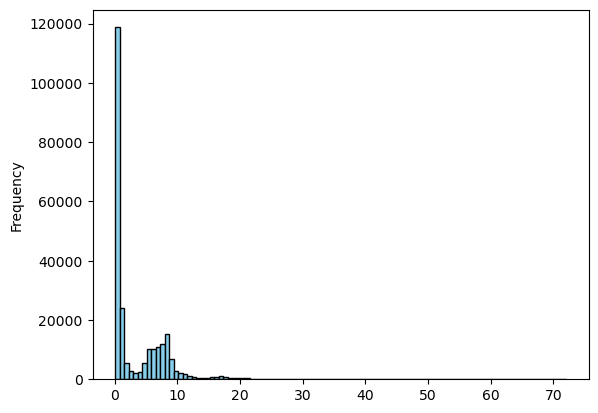

In [58]:
average_spread = quotes_all["spread"].mean()
median_spread = quotes_all["spread"].median()
average_relative_spread = quotes_all["relative_spread"].mean()

print(f"Average bid-ask spread: {average_spread:.4f}")
print(f"Median bid-ask spread:  {median_spread:.4f}")
print(f"Average relative spread: {average_relative_spread:.2%}")

# post-cleaning options

quotes_all["spread"].plot(kind="hist", bins=100, edgecolor="black", color="skyblue")
print(quotes_all["spread"].quantile([0.5, 0.75, 0.9, 0.95, 0.995]))

print("Min spread:", min(quotes_all["spread"]))
print("Max spread:", max(quotes_all["spread"]))

## 8. Black-Scholes utilities

The forward-form Black-Scholes price is

$$
C=D\left(FN(d_1)-KN(d_2)\right).
$$

The spot delta is

$$
\Delta_{\mathrm{call}}
=
D\frac{F}{S}N(d_1).
$$

Black-Scholes is used only to:

- convert market prices into implied volatility;
- construct total implied variance;
- construct calibration weights;
- validate the PDE when local volatility is constant.

In [59]:
def bs_price(cp_flag, forward, strike, T, discount, sigma):
    cp_flag = np.asarray(cp_flag)
    forward = np.asarray(forward, dtype=float)
    strike = np.asarray(strike, dtype=float)
    T = np.asarray(T, dtype=float)
    discount = np.asarray(discount, dtype=float)
    sigma = np.asarray(sigma, dtype=float)

    sqrt_T = np.sqrt(T)

    d1 = (
        np.log(forward / strike)
        + 0.5 * sigma**2 * T
    ) / (sigma * sqrt_T)

    d2 = d1 - sigma * sqrt_T

    call = discount * (
        forward * norm.cdf(d1)
        - strike * norm.cdf(d2)
    )

    put = discount * (
        strike * norm.cdf(-d2)
        - forward * norm.cdf(-d1)
    )

    return np.where(cp_flag == "C", call, put)


def bs_delta(cp_flag, spot, forward, strike, T, discount, sigma):
    cp_flag = np.asarray(cp_flag)
    spot = np.asarray(spot, dtype=float)
    forward = np.asarray(forward, dtype=float)
    strike = np.asarray(strike, dtype=float)
    T = np.asarray(T, dtype=float)
    discount = np.asarray(discount, dtype=float)
    sigma = np.asarray(sigma, dtype=float)

    sqrt_T = np.sqrt(T)

    d1 = (
        np.log(forward / strike)
        + 0.5 * sigma**2 * T
    ) / (sigma * sqrt_T)

    carry_discount = discount * forward / spot

    call_delta = carry_discount * norm.cdf(d1)
    put_delta = carry_discount * (norm.cdf(d1) - 1.0)

    return np.where(cp_flag == "C", call_delta, put_delta)


def bs_vega(forward, strike, T, discount, sigma):
    forward = np.asarray(forward, dtype=float)
    strike = np.asarray(strike, dtype=float)
    T = np.asarray(T, dtype=float)
    discount = np.asarray(discount, dtype=float)
    sigma = np.asarray(sigma, dtype=float)

    sqrt_T = np.sqrt(T)

    d1 = (
        np.log(forward / strike)
        + 0.5 * sigma**2 * T
    ) / (sigma * sqrt_T)

    return discount * forward * norm.pdf(d1) * sqrt_T


def implied_volatility_from_price(
    cp_flag,
    forward,
    strike,
    T,
    discount,
    market_price,
):
    def pricing_error(sigma):
        model_price = bs_price(
            cp_flag,
            forward,
            strike,
            T,
            discount,
            sigma,
        )
        return float(model_price - market_price)

    try:
        return brentq(pricing_error, 0.001, 5.0)
    except ValueError:
        return np.nan

## 9. Build common one-trading-day evaluation pairs

A quote on date $t$ is paired with the same `optionid` on the next SPX trading date.

Reappearance after a longer gap is not treated as a one-day observation.

In [60]:
trading_dates = sorted(spot["date"].dropna().unique())

next_date_map = {
    trading_dates[i]: trading_dates[i + 1]
    for i in range(len(trading_dates) - 1)
}

today = quotes_all.copy()
today["date_next"] = today["date"].map(next_date_map)

# if there's no tomorrow's quote, today's quote isn't kept as well since we're building pairs
today = today.dropna(subset=["date_next"]).copy()  

tomorrow_columns = [
    "optionid",
    "date",
    "exdate",
    "cp_flag",
    "strike",
    "mid",
    "best_bid",
    "best_offer",
    "spot",
    "forward_price",
    "rate",
    "discount",
    "T",
    "dte",
    "moneyness",
    "log_moneyness",
    "is_otm",
]

tomorrow = quotes_all[tomorrow_columns].copy()

tomorrow = tomorrow.rename(
    columns={
        "date": "date_next",
        "exdate": "exdate_next",
        "cp_flag": "cp_flag_next",
        "strike": "strike_next",
        "mid": "mid_next",
        "best_bid": "best_bid_next",
        "best_offer": "best_offer_next",
        "spot": "spot_next",
        "forward_price": "forward_price_next",
        "rate": "rate_next",
        "discount": "discount_next",
        "T": "T_next",
        "dte": "dte_next",
        "moneyness": "moneyness_next",
        "log_moneyness": "log_moneyness_next",
        "is_otm": "is_otm_next",
    }
)

evaluation_pairs = today.merge(
    tomorrow,
    on=["optionid", "date_next"],
    how="inner",
    validate="one_to_one",
)

evaluation_pairs["pair_id"] = (
    evaluation_pairs["date"].dt.strftime("%Y-%m-%d")
    + "|"
    + evaluation_pairs["date_next"].dt.strftime("%Y-%m-%d")
    + "|"
    + evaluation_pairs["optionid"].astype("Int64").astype(str)
)

evaluation_pairs["option_change"] = (
    evaluation_pairs["mid_next"] - evaluation_pairs["mid"]
)

print(f"Common candidate one-day pairs: {len(evaluation_pairs):,}")
print(f"Current dates represented: {evaluation_pairs['date'].nunique()}")

Common candidate one-day pairs: 224,566
Current dates represented: 19


## 10. Common metric helper

This helper reports the metrics used for evaluating and comparing model performance:

- next-day midpoint RMSE and MAE;
- proportion inside the next-day bid-ask interval;
- average distance outside the next-day bid-ask interval;
- hedging RMSE, MAE and bias.

In [61]:
def summarise_model(
    data,
    price_error_column,
    model_price_column,
    hedge_error_column=None,
):
    price_error = data[price_error_column]

    inside_bid_ask = data[model_price_column].between(
        data["best_bid_next"],
        data["best_offer_next"],
    )

    outside_spread_error = np.maximum(
        data["best_bid_next"] - data[model_price_column],
        data[model_price_column] - data["best_offer_next"],
    )
    outside_spread_error = np.maximum(outside_spread_error, 0.0)

    result = {
        "number_of_pairs": len(data),
        "next_day_price_rmse": np.sqrt(np.mean(price_error**2)),
        "next_day_price_mae": np.mean(np.abs(price_error)),
        "next_day_inside_bid_ask": inside_bid_ask.mean(),
        "next_day_outside_spread_mae": outside_spread_error.mean(),
        "unhedged_mae": data["option_change"].abs().mean(),
    }

    if hedge_error_column is not None:
        hedge_error = data[hedge_error_column]

        result["hedging_rmse"] = np.sqrt(np.mean(hedge_error**2))
        result["hedging_mae"] = np.mean(np.abs(hedge_error))
        result["hedging_bias"] = hedge_error.mean()
        result["hedging_improvement"] = (
            1.0
            - result["hedging_mae"] / result["unhedged_mae"]
        )

    return pd.Series(result)

# Local-volatility model

## 11. Construct market total implied variance and calibration weights

For every calibration quote,

$$
w_{\mathrm{mkt}}(k,T)
=
\sigma_{\mathrm{BS,mkt}}^2(k,T)T.
$$

The primary weight is

$$
\omega_i
=
\frac{1}
{\left(w_i^{\mathrm{ask}}-w_i^{\mathrm{bid}}\right)^2+\varepsilon^2}.
$$

The bid and ask implied volatilities are recovered using the same forward, discount factor and Black-Scholes convention as the model.

A second weight, Black-Scholes Vega squared, is also constructed for an optional sensitivity fit. It is not silently substituted for the primary weight.

In [63]:
calibration_cache = (
    CACHE_FOLDER / "calibration_quotes.parquet"
)

if calibration_cache.exists():
    print("Loading cached calibration quotes.")
    calibration_quotes = pd.read_parquet(
        calibration_cache
    )

else:
    calibration_quotes = calibration_quotes.copy()

    calibration_quotes["market_iv"] = pd.to_numeric(
        calibration_quotes["impl_volatility"],
        errors="coerce",
    )

    valid_vendor_iv = calibration_quotes["market_iv"].between(0.001, 5.0)

    for index in calibration_quotes.index[~valid_vendor_iv]:
        row = calibration_quotes.loc[index]

        calibration_quotes.loc[index, "market_iv"] = (
            implied_volatility_from_price(
                row["cp_flag"],
                row["forward_price"],
                row["strike"],
                row["T"],
                row["discount"],
                row["mid"],
            )
        )

    calibration_quotes["bid_iv"] = np.nan
    calibration_quotes["ask_iv"] = np.nan

    bid_iv_values = []
    ask_iv_values = []

    rows = calibration_quotes.itertuples(index=False)


    for row in tqdm(
        rows,
        total=len(calibration_quotes),
        desc="Computing bid and ask implied volatilities",
    ):
        bid_iv = implied_volatility_from_price(
            row.cp_flag,
            row.forward_price,
            row.strike,
            row.T,
            row.discount,
            row.best_bid,
        )

        ask_iv = implied_volatility_from_price(
            row.cp_flag,
            row.forward_price,
            row.strike,
            row.T,
            row.discount,
            row.best_offer,
        )

        bid_iv_values.append(bid_iv)
        ask_iv_values.append(ask_iv)


    calibration_quotes["bid_iv"] = bid_iv_values
    calibration_quotes["ask_iv"] = ask_iv_values

    calibration_quotes["market_total_variance"] = (
        calibration_quotes["market_iv"]**2
        * calibration_quotes["T"]
    )

    calibration_quotes["bid_total_variance"] = (
        calibration_quotes["bid_iv"]**2
        * calibration_quotes["T"]
    )

    calibration_quotes["ask_total_variance"] = (
        calibration_quotes["ask_iv"]**2
        * calibration_quotes["T"]
    )

    # this is w_ask - w_bid
    calibration_quotes["total_variance_width"] = (
        calibration_quotes["ask_total_variance"]
        - calibration_quotes["bid_total_variance"]
    )

    calibration_quotes["model_vega"] = bs_vega(
        calibration_quotes["forward_price"],
        calibration_quotes["strike"],
        calibration_quotes["T"],
        calibration_quotes["discount"],
        calibration_quotes["market_iv"],
    )

    rows_before_weight_filter = len(calibration_quotes)

    # calibration quotes cleaning
    valid_calibration_row = (
        calibration_quotes["market_iv"].between(0.001, 5.0)
        & calibration_quotes["bid_iv"].between(0.001, 5.0)
        & calibration_quotes["ask_iv"].between(0.001, 5.0)
        & calibration_quotes["total_variance_width"].gt(0)
        & calibration_quotes["market_total_variance"].gt(0)
    )

    calibration_quotes = calibration_quotes.loc[
        valid_calibration_row
    ].copy()

    # this is NOT a single number
    width_used = np.maximum(
        calibration_quotes["total_variance_width"],
        TOTAL_VARIANCE_WIDTH_FLOOR,
    )

    calibration_quotes["raw_bid_ask_weight"] = 1.0 / width_used**2
    calibration_quotes["raw_vega_weight"] = calibration_quotes["model_vega"]**2


    def normalise_weight_series(weight_series):
        median_weight = weight_series.median()

        if not np.isfinite(median_weight) or median_weight <= 0:
            return pd.Series(1.0, index=weight_series.index)

        normalised = weight_series / median_weight

        return normalised.clip(
            lower=MIN_NORMALISED_WEIGHT,
            upper=MAX_NORMALISED_WEIGHT,
        )


    calibration_quotes["bid_ask_weight"] = (
        calibration_quotes.groupby("date")["raw_bid_ask_weight"]
        .transform(normalise_weight_series)
    )

    calibration_quotes["vega_squared_weight"] = (
        calibration_quotes.groupby("date")["raw_vega_weight"]
        .transform(normalise_weight_series)
    )

    if WEIGHT_MODE == "bid_ask_total_variance":
        calibration_quotes["fit_weight"] = (
            calibration_quotes["bid_ask_weight"]
        )
    elif WEIGHT_MODE == "vega_squared":
        calibration_quotes["fit_weight"] = (
            calibration_quotes["vega_squared_weight"]
        )
    else:
        raise ValueError(
            "WEIGHT_MODE must be 'bid_ask_total_variance' or 'vega_squared'."
        )


print(f"Calibration rows before IV-weight filter: {rows_before_weight_filter:,}")
print(f"Calibration rows after IV-weight filter:  {len(calibration_quotes):,}")
print("Weight mode:", WEIGHT_MODE)
print(calibration_quotes["fit_weight"].describe())


calibration_quotes.to_parquet(
    CACHE_FOLDER / "calibration_quotes.parquet",
    index=False,
)

Loading cached calibration quotes.
Calibration rows before IV-weight filter: 125,746
Calibration rows after IV-weight filter:  125,746
Weight mode: bid_ask_total_variance
count    125746.000000
mean          3.740604
std           5.665080
min           0.050000
25%           0.242327
50%           1.000000
75%           4.383971
max          20.000000
Name: fit_weight, dtype: float64


## 12. SSVI specification and daily calibration  PROBLEMATIC

The notebook uses the SSVI total implied variance surface

$$
w(k,\theta)
=
\frac{\theta}{2}
\left[
1+\rho\varphi(\theta)k
+
\sqrt{
\left(\varphi(\theta)k+\rho\right)^2
+1-\rho^2
}
\right],
$$

where

$$
\theta(T)=w(0,T)
$$

is at-the-money total implied variance.

The Heston-like backbone is

$$
\varphi(\theta)
=
\frac{1}{\lambda\theta}
\left[
1-
\frac{1-e^{-\lambda\theta}}{\lambda\theta}
\right].
$$

This is the first backbone implemented in Jack Jacquier's SSVI notebook.

For this backbone, the Gatheral-Jacquier sufficient static-arbitrage conditions are satisfied when:

1. $\theta(T)$ is non-decreasing;
2. $|\rho|<1$;
3. $\lambda\geq(1+|\rho|)/4$.

The code enforces these three conditions by construction:

- positive increments generate the maturity values of $\theta$;
- `tanh` generates $\rho$;
- a positive addition is placed above the lower bound for $\lambda$.

A monotone PCHIP interpolator, anchored at $(0,0)$, gives the continuous function $\theta(T)$ and its derivative.

In [42]:
def phi_heston_like(theta, lambda_ssvi):
    theta = np.asarray(theta, dtype=float)
    z = lambda_ssvi * theta

    small_z = np.abs(z) < 1e-5

    direct_value = (
        z - 1.0 + np.exp(-z)
    ) / (z * z)

    series_value = (
        0.5
        - z / 6.0
        + z**2 / 24.0
        - z**3 / 120.0
        + z**4 / 720.0
    )

    return np.where(small_z, series_value, direct_value)


def phi_heston_like_derivative(theta, lambda_ssvi):
    theta = np.asarray(theta, dtype=float)
    z = lambda_ssvi * theta

    small_z = np.abs(z) < 1e-5

    direct_value = (
        lambda_ssvi
        * (-z + 2.0 - (z + 2.0) * np.exp(-z))
        / z**3
    )

    series_value = lambda_ssvi * (
        -1.0 / 6.0
        + z / 12.0
        - z**2 / 40.0
        + z**3 / 180.0
        - z**4 / 1008.0
    )

    return np.where(small_z, series_value, direct_value)


def ssvi_total_variance(k, theta, rho, lambda_ssvi):
    k = np.asarray(k, dtype=float)
    theta = np.asarray(theta, dtype=float)

    phi = phi_heston_like(theta, lambda_ssvi)
    x = phi * k

    square_root = np.sqrt(
        x * x + 2.0 * rho * x + 1.0
    )

    return 0.5 * theta * (
        1.0
        + rho * x
        + square_root
    )


def initial_theta_values(day_data):
    rows = []

    for maturity, maturity_data in day_data.groupby("T"):
        near_atm = maturity_data.loc[
            maturity_data["log_moneyness"].abs().le(0.05)
        ]

        if len(near_atm) < 2:
            nearest_rows = np.argsort(
                maturity_data["log_moneyness"].abs().to_numpy()
            )[:3]

            near_atm = maturity_data.iloc[nearest_rows]

        theta_guess = np.average(
            near_atm["market_total_variance"],
            weights=near_atm["fit_weight"],
        )

        rows.append((float(maturity), float(theta_guess)))

    rows = sorted(rows)

    maturities = np.array([row[0] for row in rows])
    theta = np.array([row[1] for row in rows])

    theta = np.maximum.accumulate(
        np.maximum(theta, 1e-6)
    )

    for index in range(1, len(theta)):
        theta[index] = max(
            theta[index],
            theta[index - 1] + 1e-6,
        )

    return maturities, theta


def unpack_ssvi_parameters(raw_parameters, number_of_maturities):
    log_increments = raw_parameters[:number_of_maturities]
    theta_increments = np.exp(log_increments)
    theta = np.cumsum(theta_increments)

    rho = np.tanh(raw_parameters[number_of_maturities])

    smooth_absolute_rho = np.sqrt(rho**2 + 1e-12)
    lambda_lower_bound = (1.0 + smooth_absolute_rho) / 4.0

    lambda_ssvi = (
        lambda_lower_bound
        + np.exp(raw_parameters[number_of_maturities + 1])
    )

    return theta, rho, lambda_ssvi


def fit_ssvi_one_date(day_data):
    quotes_per_expiry = day_data.groupby("T").size()

    eligible_maturities = quotes_per_expiry.loc[
        quotes_per_expiry.ge(MIN_QUOTES_PER_EXPIRY)
    ].index

    fit_data = day_data.loc[
        day_data["T"].isin(eligible_maturities)
    ].copy()

    if fit_data["T"].nunique() < MIN_EXPIRIES_PER_DATE:
        return None, None, None

    maturities, theta_initial = initial_theta_values(fit_data)

    maturity_to_index = {
        maturity: index
        for index, maturity in enumerate(maturities)
    }

    maturity_index = (
        fit_data["T"]
        .map(maturity_to_index)
        .to_numpy(dtype=int)
    )

    k_market = fit_data["log_moneyness"].to_numpy(dtype=float)
    w_market = fit_data["market_total_variance"].to_numpy(dtype=float)
    square_root_weight = np.sqrt(
        fit_data["fit_weight"].to_numpy(dtype=float)
    )

    theta_increments_initial = np.diff(
        np.concatenate(([0.0], theta_initial))
    )

    rho_initial = -0.50
    lambda_initial = 1.00
    lambda_floor_initial = (1.0 + abs(rho_initial)) / 4.0

    raw_initial = np.concatenate(
        [
            np.log(np.maximum(theta_increments_initial, 1e-7)),
            [np.arctanh(rho_initial)],
            [
                np.log(
                    max(
                        lambda_initial - lambda_floor_initial,
                        1e-4,
                    )
                )
            ],
        ]
    )

    number_of_maturities = len(maturities)

    lower_bounds = np.concatenate(
        [
            np.full(number_of_maturities, np.log(1e-7)),
            [-3.8],
            [np.log(1e-4)],
        ]
    )

    upper_bounds = np.concatenate(
        [
            np.full(number_of_maturities, np.log(0.50)),
            [3.8],
            [np.log(100.0)],
        ]
    )

    def residuals(raw_parameters):
        theta, rho, lambda_ssvi = unpack_ssvi_parameters(
            raw_parameters,
            number_of_maturities,
        )

        fitted_total_variance = ssvi_total_variance(
            k_market,
            theta[maturity_index],
            rho,
            lambda_ssvi,
        )

        return square_root_weight * (
            fitted_total_variance - w_market
        )

    result = least_squares(
        residuals,
        raw_initial,
        bounds=(lower_bounds, upper_bounds),
        max_nfev=MAX_FIT_EVALUATIONS,
    )

    theta, rho, lambda_ssvi = unpack_ssvi_parameters(
        result.x,
        number_of_maturities,
    )

    time_nodes = np.concatenate(([0.0], maturities))
    theta_nodes = np.concatenate(([0.0], theta))

    theta_curve = PchipInterpolator(
        time_nodes,
        theta_nodes,
        extrapolate=False,
    )

    model = {
        "maturities": maturities,
        "theta": theta,
        "rho": float(rho),
        "lambda_ssvi": float(lambda_ssvi),
        "theta_curve": theta_curve,
        "theta_derivative": theta_curve.derivative(),
    }

    fitted_total_variance = ssvi_total_variance(
        k_market,
        theta[maturity_index],
        rho,
        lambda_ssvi,
    )

    fit_error = fitted_total_variance - w_market

    diagnostic = {
        "number_of_quotes": len(fit_data),
        "number_of_expiries": number_of_maturities,
        "fit_success": bool(result.success),
        "fit_message": result.message,
        "rho": float(rho),
        "lambda_ssvi": float(lambda_ssvi),
        "total_variance_rmse": float(
            np.sqrt(np.mean(fit_error**2))
        ),
        "total_variance_mae": float(
            np.mean(np.abs(fit_error))
        ),
        "weighted_root_mean_square_error": float(
            np.sqrt(np.mean(residuals(result.x)**2))
        ),
        "maximum_maturity": float(maturities.max()),
    }

    parameter_rows = []

    for maturity, theta_value in zip(maturities, theta):
        parameter_rows.append(
            {
                "T": maturity,
                "theta": theta_value,
                "rho": float(rho),
                "lambda_ssvi": float(lambda_ssvi),
            }
        )

    parameter_table = pd.DataFrame(parameter_rows)

    return model, diagnostic, parameter_table


def fit_all_ssvi_dates(calibration_data):
    models = {}
    diagnostics = []
    parameter_tables = []

    dates = sorted(calibration_data["date"].unique())

    for date in tqdm(
        dates,
        total=len(dates),
        desc="Fitting daily SSVI surfaces",
    ):
        day_data = calibration_data.loc[
            calibration_data["date"].eq(date)
        ].copy()

        model, diagnostic, parameter_table = fit_ssvi_one_date(
            day_data
        )

        if model is None:
            continue

        models[pd.Timestamp(date)] = model

        diagnostic["date"] = pd.Timestamp(date)
        diagnostics.append(diagnostic)

        parameter_table["date"] = pd.Timestamp(date)
        parameter_tables.append(parameter_table)

    diagnostic_table = pd.DataFrame(diagnostics)

    if parameter_tables:
        parameter_table = pd.concat(
            parameter_tables,
            ignore_index=True,
        )
    else:
        parameter_table = pd.DataFrame()

    return models, diagnostic_table, parameter_table


def rebuild_ssvi_models(parameter_table):
    models = {}

    for date, day_parameters in parameter_table.groupby("date"):
        day_parameters = day_parameters.sort_values("T")

        maturities = day_parameters["T"].to_numpy(dtype=float)
        theta = day_parameters["theta"].to_numpy(dtype=float)

        rho = float(day_parameters["rho"].iloc[0])
        lambda_ssvi = float(
            day_parameters["lambda_ssvi"].iloc[0]
        )

        time_nodes = np.concatenate(([0.0], maturities))
        theta_nodes = np.concatenate(([0.0], theta))

        theta_curve = PchipInterpolator(
            time_nodes,
            theta_nodes,
            extrapolate=False,
        )

        models[pd.Timestamp(date)] = {
            "maturities": maturities,
            "theta": theta,
            "rho": rho,
            "lambda_ssvi": lambda_ssvi,
            "theta_curve": theta_curve,
            "theta_derivative": theta_curve.derivative(),
        }

    return models


parameter_cache = CACHE_FOLDER / "ssvi_parameters.csv"
diagnostic_cache = CACHE_FOLDER / "ssvi_fit_diagnostics.csv"

if parameter_cache.exists() and diagnostic_cache.exists():
    print("Loading cached SSVI fits.")

    ssvi_parameters = pd.read_csv(
        parameter_cache,
        parse_dates=["date"],
    )

    ssvi_fit_diagnostics = pd.read_csv(
        diagnostic_cache,
        parse_dates=["date"],
    )

    ssvi_models = rebuild_ssvi_models(ssvi_parameters)

else:
    ssvi_models, ssvi_fit_diagnostics, ssvi_parameters = (
        fit_all_ssvi_dates(calibration_quotes)
    )

    ssvi_parameters.to_csv(
        parameter_cache,
        index=False,
    )

    ssvi_fit_diagnostics.to_csv(
        diagnostic_cache,
        index=False,
    )



print("Saved SSVI calibration cache.")

print(f"Successful SSVI dates: {len(ssvi_models)}")
display(ssvi_fit_diagnostics.head())

Fitting daily SSVI surfaces:   0%|          | 0/20 [00:00<?, ?it/s]

Saved SSVI calibration cache.
Successful SSVI dates: 20


,number_of_quotes,number_of_expiries,fit_success,fit_message,rho,lambda_ssvi,total_variance_rmse,total_variance_mae,weighted_root_mean_square_error,maximum_maturity,date
0,5934,36,True,`ftol` termination condition is satisfied.,-0.998999,0.510549,0.005333,0.003397,0.002481,0.978082,2024-03-01
1,6205,36,True,`ftol` termination condition is satisfied.,-0.998999,0.505198,0.005225,0.003289,0.002334,0.969863,2024-03-04
2,6191,36,True,`ftol` termination condition is satisfied.,-0.999000,0.500534,0.005425,0.003394,0.002315,0.967123,2024-03-05
3,6156,36,True,`ftol` termination condition is satisfied.,-0.999000,0.500000,0.005419,0.003400,0.002424,0.964384,2024-03-06
4,6108,36,True,`ftol` termination condition is satisfied.,-0.999000,0.504450,0.005270,0.003367,0.002379,0.961644,2024-03-07


## 13. Analytic derivatives, Dupire local variance and validity diagnostics

Write

$$
x=\varphi(\theta)k,
\qquad
R=\sqrt{x^2+2\rho x+1}.
$$

Then

$$
w_k
=
\frac{\theta\varphi}{2}
\left[
\rho+\frac{x+\rho}{R}
\right],
$$

and

$$
w_{kk}
=
\frac{\theta\varphi^2}{2}
\frac{1-\rho^2}{R^3}.
$$

The maturity derivative is obtained by the chain rule:

$$
w_T=w_\theta\theta'(T).
$$

The Dupire denominator is

$$
g(k,T)
=
\left(1-\frac{k w_k}{2w}\right)^2
-
\frac{w_k^2}{4}
\left(\frac1w+\frac14\right)
+
\frac12w_{kk}.
$$

Local variance is

$$
\sigma_{\mathrm{loc}}^2(k,T)
=
\frac{w_T(k,T)}{g(k,T)}.
$$

The two essential numerical conditions are

$$
w_T\geq0,
\qquad
g>0.
$$

The first is the calendar-spread condition. The second is the butterfly condition and is equivalent to non-negative risk-neutral density for the fitted slice.

Local-volatility flooring and capping are numerical safeguards used only after the raw values have been recorded in the diagnostics.

In [43]:
def ssvi_surface_terms(
    k,
    theta,
    theta_time_derivative,
    rho,
    lambda_ssvi,
):
    k = np.asarray(k, dtype=float)
    theta = np.asarray(theta, dtype=float)
    theta_time_derivative = np.asarray(
        theta_time_derivative,
        dtype=float,
    )

    theta_safe = np.maximum(theta, 1e-12)

    phi = phi_heston_like(theta_safe, lambda_ssvi)
    phi_theta = phi_heston_like_derivative(
        theta_safe,
        lambda_ssvi,
    )

    x = phi * k

    square_root = np.sqrt(
        x * x + 2.0 * rho * x + 1.0
    )

    slope_factor = rho + (x + rho) / square_root

    w = 0.5 * theta_safe * (
        1.0 + rho * x + square_root
    )

    w_k = (
        0.5
        * theta_safe
        * phi
        * slope_factor
    )

    w_kk = (
        0.5
        * theta_safe
        * phi**2
        * (1.0 - rho**2)
        / square_root**3
    )

    w_theta = (
        0.5 * (1.0 + rho * x + square_root)
        + 0.5
        * theta_safe
        * phi_theta
        * k
        * slope_factor
    )

    w_T = w_theta * theta_time_derivative

    dupire_denominator = (
        (
            1.0
            - k * w_k / (2.0 * w)
        )**2
        - 0.25
        * w_k**2
        * (1.0 / w + 0.25)
        + 0.5 * w_kk
    )

    local_variance = w_T / dupire_denominator

    return {
        "w": w,
        "w_k": w_k,
        "w_kk": w_kk,
        "w_theta": w_theta,
        "w_T": w_T,
        "dupire_denominator": dupire_denominator,
        "local_variance": local_variance,
    }


def ssvi_terms_from_model(model, k, T):
    T_used = max(float(T), 1e-8)

    theta = float(model["theta_curve"](T_used))
    theta_time_derivative = float(
        model["theta_derivative"](T_used)
    )

    return ssvi_surface_terms(
        k,
        theta,
        theta_time_derivative,
        model["rho"],
        model["lambda_ssvi"],
    )


def ssvi_local_volatility(model, k, T, apply_safeguard=True):
    terms = ssvi_terms_from_model(model, k, T)

    local_variance = np.asarray(
        terms["local_variance"],
        dtype=float,
    )

    invalid = (
        np.asarray(terms["w_T"]) < -1e-10
    ) | (
        np.asarray(terms["dupire_denominator"]) <= 0
    )

    local_variance = np.where(
        invalid,
        np.nan,
        np.maximum(local_variance, 0.0),
    )

    local_volatility = np.sqrt(local_variance)

    if apply_safeguard:
        local_volatility = np.clip(
            local_volatility,
            LOCAL_VOLATILITY_MIN,
            LOCAL_VOLATILITY_MAX,
        )

    return local_volatility


def diagnose_one_ssvi_model(model):
    maturity_grid = np.linspace(
        max(1.0 / 365.0, model["maturities"].min() / 5.0),
        model["maturities"].max(),
        30,
    )

    k_grid = np.linspace(
        -DIAGNOSTIC_K_MAX,
        DIAGNOSTIC_K_MAX,
        121,
    )

    all_w_T = []
    all_denominator = []
    all_local_variance = []

    for maturity in maturity_grid:
        terms = ssvi_terms_from_model(
            model,
            k_grid,
            maturity,
        )

        all_w_T.extend(np.ravel(terms["w_T"]))
        all_denominator.extend(
            np.ravel(terms["dupire_denominator"])
        )
        all_local_variance.extend(
            np.ravel(terms["local_variance"])
        )

    all_w_T = np.asarray(all_w_T, dtype=float)
    all_denominator = np.asarray(
        all_denominator,
        dtype=float,
    )
    all_local_variance = np.asarray(
        all_local_variance,
        dtype=float,
    )

    theta = model["theta"]
    phi = phi_heston_like(
        theta,
        model["lambda_ssvi"],
    )

    sufficient_margin_one = (
        4.0
        - theta
        * phi
        * (1.0 + abs(model["rho"]))
    )

    sufficient_margin_two = (
        4.0
        - theta
        * phi**2
        * (1.0 + abs(model["rho"]))
    )

    valid_local_variance = (
        np.isfinite(all_local_variance)
        & (all_local_variance >= 0)
    )

    raw_local_volatility = np.sqrt(
        np.maximum(
            all_local_variance[valid_local_variance],
            0.0,
        )
    )

    if len(raw_local_volatility) == 0:
        raw_local_volatility = np.array([np.nan])
        safeguard_fraction = np.nan
    else:
        outside_safeguard = (
            (raw_local_volatility < LOCAL_VOLATILITY_MIN)
            | (raw_local_volatility > LOCAL_VOLATILITY_MAX)
        )
        safeguard_fraction = float(
            np.mean(outside_safeguard)
        )

    return {
        "minimum_theta_increment": float(
            np.min(np.diff(np.concatenate(([0.0], theta))))
        ),
        "minimum_w_T": float(np.nanmin(all_w_T)),
        "fraction_w_T_negative": float(
            np.mean(all_w_T < -1e-10)
        ),
        "minimum_dupire_denominator": float(
            np.nanmin(all_denominator)
        ),
        "fraction_dupire_denominator_nonpositive": float(
            np.mean(all_denominator <= 0)
        ),
        "minimum_sufficient_butterfly_margin_one": float(
            np.min(sufficient_margin_one)
        ),
        "minimum_sufficient_butterfly_margin_two": float(
            np.min(sufficient_margin_two)
        ),
        "local_volatility_median": float(
            np.nanmedian(raw_local_volatility)
        ),
        "local_volatility_95_percentile": float(
            np.nanquantile(raw_local_volatility, 0.95)
        ),
        "local_volatility_maximum": float(
            np.nanmax(raw_local_volatility)
        ),
        "fraction_local_volatility_safeguarded": (
            safeguard_fraction
        ),
    }


validity_rows = []
validity_cache = (
        CACHE_FOLDER / "ssvi_validity_diagnostics.csv"
    )

for date, model in tqdm(
    ssvi_models.items(),
    total=len(ssvi_models),
    desc="Running Dupire diagnostics",
):

    if validity_cache.exists():
        print("Loading cached Dupire diagnostics.")

        ssvi_validity_diagnostics = pd.read_csv(
            validity_cache,
            parse_dates=["date"],
        )

    else:
        validity_rows = []

        for date, model in tqdm(
            ssvi_models.items(),
            total=len(ssvi_models),
            desc="Running Dupire diagnostics",
        ):
            row = diagnose_one_ssvi_model(model)
            row["date"] = pd.Timestamp(date)
            validity_rows.append(row)

        ssvi_validity_diagnostics = pd.DataFrame(
            validity_rows
        )

        ssvi_validity_diagnostics.to_csv(
            validity_cache,
            index=False,
        )

ssvi_validity_diagnostics = pd.DataFrame(validity_rows)

print("SSVI and Dupire validity diagnostics")
display(ssvi_validity_diagnostics.describe().T)

Running Dupire diagnostics:   0%|          | 0/20 [00:00<?, ?it/s]

Running Dupire diagnostics:   0%|          | 0/20 [00:00<?, ?it/s]

Loading cached Dupire diagnostics.
Loading cached Dupire diagnostics.
Loading cached Dupire diagnostics.
Loading cached Dupire diagnostics.
Loading cached Dupire diagnostics.
Loading cached Dupire diagnostics.
Loading cached Dupire diagnostics.
Loading cached Dupire diagnostics.
Loading cached Dupire diagnostics.
Loading cached Dupire diagnostics.
Loading cached Dupire diagnostics.
Loading cached Dupire diagnostics.
Loading cached Dupire diagnostics.
Loading cached Dupire diagnostics.
Loading cached Dupire diagnostics.
Loading cached Dupire diagnostics.
Loading cached Dupire diagnostics.
Loading cached Dupire diagnostics.
Loading cached Dupire diagnostics.
SSVI and Dupire validity diagnostics


,count,mean,min,25%,50%,75%,max,std
minimum_theta_increment,20.0,0.000002,0.0,0.000001,0.000001,0.000002,0.000003,0.000001
minimum_w_T,20.0,0.000251,-0.0,-0.0,0.000091,0.000353,0.001597,0.000407
fraction_w_T_negative,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
minimum_dupire_denominator,20.0,0.782081,0.782042,0.782067,0.782083,0.782095,0.782119,0.000021
fraction_dupire_denominator_nonpositive,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
minimum_sufficient_butterfly_margin_one,20.0,3.972858,3.97102,3.972109,3.972737,3.9735,3.974472,0.000963
minimum_sufficient_butterfly_margin_two,20.0,3.986492,3.985581,3.986121,3.986431,3.986809,3.987292,0.000477
local_volatility_median,20.0,0.151065,0.137466,0.147017,0.15071,0.155424,0.16535,0.006496
local_volatility_95_percentile,20.0,0.283608,0.249234,0.273352,0.284444,0.296982,0.320079,0.0193
local_volatility_maximum,20.0,0.398031,0.315781,0.356819,0.409524,0.429336,0.475917,0.048988


### Analytic derivative check

This small test compares the analytic derivatives with central finite differences.

It is a code validation test, not part of the model calibration.

In [44]:
def check_ssvi_derivatives(model):
    maturity = float(np.median(model["maturities"]))
    k = 0.10

    k_step = 1e-5
    T_step = min(1e-5, maturity / 20.0)

    terms = ssvi_terms_from_model(model, k, maturity)

    w_left = ssvi_terms_from_model(
        model,
        k - k_step,
        maturity,
    )["w"]

    w_middle = terms["w"]

    w_right = ssvi_terms_from_model(
        model,
        k + k_step,
        maturity,
    )["w"]

    w_k_finite_difference = (
        w_right - w_left
    ) / (2.0 * k_step)

    w_kk_finite_difference = (
        w_right
        - 2.0 * w_middle
        + w_left
    ) / k_step**2

    w_T_finite_difference = (
        ssvi_terms_from_model(
            model,
            k,
            maturity + T_step,
        )["w"]
        - ssvi_terms_from_model(
            model,
            k,
            maturity - T_step,
        )["w"]
    ) / (2.0 * T_step)

    return pd.Series(
        {
            "analytic_w_k": float(terms["w_k"]),
            "finite_difference_w_k": float(
                w_k_finite_difference
            ),
            "analytic_w_kk": float(terms["w_kk"]),
            "finite_difference_w_kk": float(
                w_kk_finite_difference
            ),
            "analytic_w_T": float(terms["w_T"]),
            "finite_difference_w_T": float(
                w_T_finite_difference
            ),
        }
    )


if ssvi_models:
    first_model = ssvi_models[sorted(ssvi_models)[0]]
    display(check_ssvi_derivatives(first_model))

analytic_w_k             -1.255986e-03
finite_difference_w_k    -1.255986e-03
analytic_w_kk             7.331040e-07
finite_difference_w_kk    7.329207e-07
analytic_w_T              1.978214e-02
finite_difference_w_T     1.978214e-02
dtype: float64

## 14. Plot one fitted total implied variance surface and its local volatility

The left plot compares observed and fitted total implied variance.

The right plot shows local volatility at selected maturities. It is intentionally a two-dimensional diagnostic rather than a decorative three-dimensional plot.

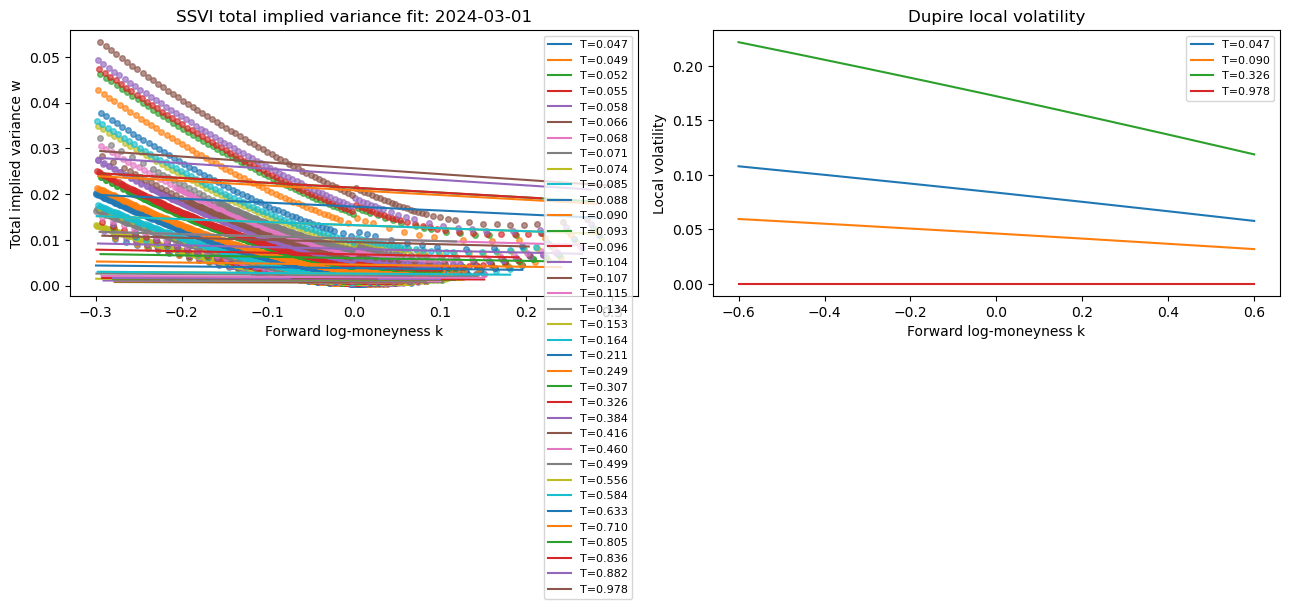

In [45]:
if ssvi_models:
    example_date = sorted(ssvi_models)[0]
    example_model = ssvi_models[example_date]

    example_quotes = calibration_quotes.loc[
        calibration_quotes["date"].eq(example_date)
    ].copy()

    figure, axes = plt.subplots(1, 2, figsize=(13, 5))

    for maturity in example_model["maturities"]:
        maturity_quotes = example_quotes.loc[
            np.isclose(example_quotes["T"], maturity)
        ].sort_values("log_moneyness")

        if maturity_quotes.empty:
            continue

        axes[0].scatter(
            maturity_quotes["log_moneyness"],
            maturity_quotes["market_total_variance"],
            s=16,
            alpha=0.65,
        )

        k_line = np.linspace(
            maturity_quotes["log_moneyness"].min(),
            maturity_quotes["log_moneyness"].max(),
            150,
        )

        theta = float(
            example_model["theta_curve"](maturity)
        )

        w_line = ssvi_total_variance(
            k_line,
            theta,
            example_model["rho"],
            example_model["lambda_ssvi"],
        )

        axes[0].plot(
            k_line,
            w_line,
            label=f"T={maturity:.3f}",
        )

    axes[0].set_title(
        f"SSVI total implied variance fit: {example_date.date()}"
    )
    axes[0].set_xlabel("Forward log-moneyness k")
    axes[0].set_ylabel("Total implied variance w")
    axes[0].legend(fontsize=8)

    selected_maturities = example_model["maturities"]
    if len(selected_maturities) > 4:
        selected_maturities = selected_maturities[
            np.linspace(
                0,
                len(selected_maturities) - 1,
                4,
            ).astype(int)
        ]

    k_line = np.linspace(
        -DIAGNOSTIC_K_MAX,
        DIAGNOSTIC_K_MAX,
        200,
    )

    for maturity in selected_maturities:
        local_volatility_line = ssvi_local_volatility(
            example_model,
            k_line,
            maturity,
            apply_safeguard=False,
        )

        axes[1].plot(
            k_line,
            local_volatility_line,
            label=f"T={maturity:.3f}",
        )

    axes[1].set_title("Dupire local volatility")
    axes[1].set_xlabel("Forward log-moneyness k")
    axes[1].set_ylabel("Local volatility")
    axes[1].legend(fontsize=8)

    plt.tight_layout()
    plt.show()

## 15. Backward local-volatility valuation PDE, Crank-Nicolson and Rannacher damping

Under the risk-neutral local-volatility model,

$$
dS_t
=
(r-q)S_t\,dt
+
\sigma_{\mathrm{loc}}(S_t,t)S_t\,dW_t.
$$

For one date-expiry group, define the effective carry

$$
c=r-q=\frac{\log(F/S_0)}{T}.
$$

This uses the observed forward and avoids separately estimating a dividend yield.

The backward local-volatility valuation PDE is

$$
V_t
+
\frac12\sigma_{\mathrm{loc}}^2(S,t)S^2V_{SS}
+
cSV_S
-rV
=
0.
$$

Using

$$
x=\log(S/S_0),
$$

the PDE becomes

$$
V_t
+
\left(c-\frac12\sigma_{\mathrm{loc}}^2\right)V_x
+
\frac12\sigma_{\mathrm{loc}}^2V_{xx}
-rV
=
0.
$$

The log-spot grid is symmetric and has an odd number of points. Therefore $x=0$, hence $S=S_0$, is exactly a grid point.

### Crank-Nicolson

Crank-Nicolson averages the spatial operator over the two ends of a time step. It is second-order accurate in time for a sufficiently smooth solution.

### Rannacher damping

The terminal payoff has a kink at the strike. The first two full Crank-Nicolson steps are therefore replaced by four implicit-Euler half-steps. Implicit Euler damps the high-frequency grid error created by the payoff kink. Crank-Nicolson is then used after the PDE has smoothed the solution.

One PDE solve handles all strikes and both option types in the same date-expiry group. The tridiagonal matrix is shared; each option payoff is a separate right-hand side.

The PDE delta is

$$
\Delta_{\mathrm{LV}}
=
V_S
=
\frac{V_x}{S}.
$$

The calibrated SSVI surface is held fixed when this derivative is computed.

In [46]:
def option_boundaries(
    strikes,
    cp_flags,
    S_min,
    S_max,
    remaining_time,
    rate,
    carry,
):
    discount_rate = np.exp(-rate * remaining_time)

    dividend_rate = rate - carry
    discount_dividend = np.exp(
        -dividend_rate * remaining_time
    )

    lower_boundary = np.zeros(len(strikes))
    upper_boundary = np.zeros(len(strikes))

    calls = cp_flags == "C"
    puts = cp_flags == "P"

    lower_boundary[calls] = 0.0

    upper_boundary[calls] = np.maximum(
        S_max * discount_dividend
        - strikes[calls] * discount_rate,
        0.0,
    )

    lower_boundary[puts] = np.maximum(
        strikes[puts] * discount_rate
        - S_min * discount_dividend,
        0.0,
    )

    upper_boundary[puts] = 0.0

    return lower_boundary, upper_boundary


def one_backward_time_step(
    value_right,
    t_right,
    t_left,
    maturity,
    x_grid,
    spot_grid,
    strikes,
    cp_flags,
    rate,
    carry,
    local_volatility_function,
    implicit_weight,
):
    time_step = t_right - t_left
    time_middle = 0.5 * (t_right + t_left)

    local_volatility = np.asarray(
        local_volatility_function(
            time_middle,
            spot_grid,
        ),
        dtype=float,
    )

    if not np.all(np.isfinite(local_volatility)):
        raise ValueError(
            "The local-volatility function returned a non-finite value."
        )

    dx = x_grid[1] - x_grid[0]

    diffusion_coefficient = 0.5 * local_volatility**2

    drift_coefficient = (
        carry - 0.5 * local_volatility**2
    )

    lower_operator = (
        diffusion_coefficient / dx**2
        - drift_coefficient / (2.0 * dx)
    )

    diagonal_operator = (
        -2.0 * diffusion_coefficient / dx**2
        - rate
    )

    upper_operator = (
        diffusion_coefficient / dx**2
        + drift_coefficient / (2.0 * dx)
    )

    inside = slice(1, len(x_grid) - 1)

    lower_left_matrix = (
        -implicit_weight
        * time_step
        * lower_operator[inside]
    )

    diagonal_left_matrix = (
        1.0
        - implicit_weight
        * time_step
        * diagonal_operator[inside]
    )

    upper_left_matrix = (
        -implicit_weight
        * time_step
        * upper_operator[inside]
    )

    explicit_weight = 1.0 - implicit_weight

    right_hand_side = (
        (
            1.0
            + explicit_weight
            * time_step
            * diagonal_operator[inside]
        )[:, None]
        * value_right[1:-1]
        + (
            explicit_weight
            * time_step
            * lower_operator[inside]
        )[:, None]
        * value_right[:-2]
        + (
            explicit_weight
            * time_step
            * upper_operator[inside]
        )[:, None]
        * value_right[2:]
    )

    remaining_time_left = maturity - t_left

    lower_boundary_left, upper_boundary_left = (
        option_boundaries(
            strikes,
            cp_flags,
            spot_grid[0],
            spot_grid[-1],
            remaining_time_left,
            rate,
            carry,
        )
    )

    right_hand_side[0] -= (
        lower_left_matrix[0]
        * lower_boundary_left
    )

    right_hand_side[-1] -= (
        upper_left_matrix[-1]
        * upper_boundary_left
    )

    number_of_interior_points = len(x_grid) - 2

    banded_matrix = np.zeros(
        (3, number_of_interior_points)
    )

    banded_matrix[0, 1:] = (
        upper_left_matrix[:-1]
    )

    banded_matrix[1] = diagonal_left_matrix

    banded_matrix[2, :-1] = (
        lower_left_matrix[1:]
    )

    value_left = value_right.copy()

    value_left[0] = lower_boundary_left
    value_left[-1] = upper_boundary_left

    value_left[1:-1] = solve_banded(
        (1, 1),
        banded_matrix,
        right_hand_side,
    )

    return value_left


def solve_local_volatility_pde_group(
    spot,
    forward,
    rate,
    maturity,
    strikes,
    cp_flags,
    local_volatility_function,
    space_points=PDE_SPACE_POINTS,
    time_steps_per_year=PDE_TIME_STEPS_PER_YEAR,
    log_spot_width=PDE_LOG_SPOT_WIDTH,
    rannacher_full_steps=RANNACHER_FULL_STEPS,
):
    strikes = np.asarray(strikes, dtype=float)
    cp_flags = np.asarray(cp_flags)

    if maturity <= 0:
        price = np.where(
            cp_flags == "C",
            np.maximum(spot - strikes, 0.0),
            np.maximum(strikes - spot, 0.0),
        )

        delta = np.where(
            cp_flags == "C",
            (spot > strikes).astype(float),
            -(spot < strikes).astype(float),
        )

        return price, delta

    if space_points % 2 == 0:
        space_points += 1

    time_steps = max(
        40,
        int(np.ceil(time_steps_per_year * maturity)),
    )

    if time_steps <= rannacher_full_steps:
        time_steps = rannacher_full_steps + 1

    carry = np.log(forward / spot) / maturity

    x_grid = np.linspace(
        -log_spot_width,
        log_spot_width,
        space_points,
    )

    spot_grid = spot * np.exp(x_grid)

    dx = x_grid[1] - x_grid[0]

    value = np.where(
        cp_flags[None, :] == "C",
        np.maximum(
            spot_grid[:, None] - strikes[None, :],
            0.0,
        ),
        np.maximum(
            strikes[None, :] - spot_grid[:, None],
            0.0,
        ),
    )

    full_time_step = maturity / time_steps
    t_right = maturity

    for step_number in range(time_steps):
        if step_number < rannacher_full_steps:
            for half_step in range(2):
                t_left = t_right - 0.5 * full_time_step

                value = one_backward_time_step(
                    value,
                    t_right,
                    t_left,
                    maturity,
                    x_grid,
                    spot_grid,
                    strikes,
                    cp_flags,
                    rate,
                    carry,
                    local_volatility_function,
                    implicit_weight=1.0,
                )

                t_right = t_left
        else:
            t_left = t_right - full_time_step

            value = one_backward_time_step(
                value,
                t_right,
                t_left,
                maturity,
                x_grid,
                spot_grid,
                strikes,
                cp_flags,
                rate,
                carry,
                local_volatility_function,
                implicit_weight=0.5,
            )

            t_right = t_left

    centre = space_points // 2

    price = value[centre].copy()

    value_x = (
        value[centre + 1]
        - value[centre - 1]
    ) / (2.0 * dx)

    delta = value_x / spot

    return price, delta


def make_ssvi_local_volatility_function(
    model,
    spot,
    forward,
    maturity,
):
    carry = np.log(forward / spot) / maturity

    def local_volatility_function(time, state_spot):
        forward_at_time = spot * np.exp(carry * time)

        state_log_moneyness = np.log(
            state_spot / forward_at_time
        )

        return ssvi_local_volatility(
            model,
            state_log_moneyness,
            time,
            apply_safeguard=True,
        )

    return local_volatility_function

## 16. Numerical validation

The PDE is not used on market data until it passes simple tests.

### Constant local volatility

When

$$
\sigma_{\mathrm{loc}}(S,t)\equiv\sigma,
$$

the PDE must recover Black-Scholes prices and deltas.

### Rannacher comparison

For a short-dated at-the-money option, compare ordinary Crank-Nicolson with Crank-Nicolson started by Rannacher damping.

### Grid convergence

Refine the log-spot and time grids and verify that the price and delta stabilise.

These tests detect PDE errors independently of SSVI calibration.

In [47]:
def constant_local_volatility_function(sigma):
    def local_volatility_function(time, state_spot):
        return np.full_like(
            state_spot,
            sigma,
            dtype=float,
        )

    return local_volatility_function


def validate_constant_local_volatility(
    maturity_test=0.50,
    space_points=PDE_SPACE_POINTS,
    time_steps_per_year=PDE_TIME_STEPS_PER_YEAR,
    rannacher_full_steps=RANNACHER_FULL_STEPS,
):
    spot_test = 100.0
    rate_test = 0.02
    dividend_test = 0.01
    sigma_test = 0.20

    carry_test = rate_test - dividend_test
    forward_test = spot_test * np.exp(
        carry_test * maturity_test
    )
    discount_test = np.exp(
        -rate_test * maturity_test
    )

    strikes_test = np.array(
        [80.0, 90.0, 100.0, 110.0, 120.0]
    )

    cp_flags_test = np.array(
        ["C", "C", "C", "C", "C"]
    )

    pde_price, pde_delta = (
        solve_local_volatility_pde_group(
            spot_test,
            forward_test,
            rate_test,
            maturity_test,
            strikes_test,
            cp_flags_test,
            constant_local_volatility_function(
                sigma_test
            ),
            space_points=space_points,
            time_steps_per_year=time_steps_per_year,
            log_spot_width=1.20,
            rannacher_full_steps=rannacher_full_steps,
        )
    )

    black_scholes_price = bs_price(
        cp_flags_test,
        forward_test,
        strikes_test,
        maturity_test,
        discount_test,
        sigma_test,
    )

    black_scholes_delta = bs_delta(
        cp_flags_test,
        spot_test,
        forward_test,
        strikes_test,
        maturity_test,
        discount_test,
        sigma_test,
    )

    return pd.DataFrame(
        {
            "strike": strikes_test,
            "pde_price": pde_price,
            "black_scholes_price": black_scholes_price,
            "price_error": pde_price - black_scholes_price,
            "pde_delta": pde_delta,
            "black_scholes_delta": black_scholes_delta,
            "delta_error": pde_delta - black_scholes_delta,
        }
    )


constant_volatility_validation = (
    validate_constant_local_volatility()
)

display(constant_volatility_validation)

print(
    "Maximum absolute price error:",
    constant_volatility_validation["price_error"].abs().max(),
)

print(
    "Maximum absolute delta error:",
    constant_volatility_validation["delta_error"].abs().max(),
)

,strike,pde_price,black_scholes_price,price_error,pde_delta,black_scholes_delta,delta_error
0,80.0,20.579664,20.579559,0.000104,0.949112,0.949145,-0.000032
1,90.0,12.050742,12.051175,-0.000433,0.798632,0.798634,-0.000001
2,100.0,5.844470,5.846717,-0.002247,0.539564,0.539531,0.000034
3,110.0,2.326763,2.327753,-0.000990,0.283678,0.283637,0.000041
4,120.0,0.770568,0.770278,0.000290,0.117897,0.117786,0.000111


Maximum absolute price error: 0.0022469669534812553
Maximum absolute delta error: 0.0001110754616223536


In [48]:
short_maturity = 30.0 / 365.0

rannacher_comparison_rows = []

for rannacher_steps in tqdm(
    [0, 2],
    desc="Comparing Rannacher settings",
):
    result = validate_constant_local_volatility(
        maturity_test=short_maturity,
        space_points=201,
        time_steps_per_year=250,
        rannacher_full_steps=rannacher_steps,
    )

    atm_row = result.loc[
        result["strike"].eq(100.0)
    ].iloc[0]

    rannacher_comparison_rows.append(
        {
            "rannacher_full_steps": rannacher_steps,
            "atm_price_error": atm_row["price_error"],
            "atm_delta_error": atm_row["delta_error"],
        }
    )

rannacher_comparison = pd.DataFrame(
    rannacher_comparison_rows
)

display(rannacher_comparison)

Comparing Rannacher settings:   0%|          | 0/2 [00:00<?, ?it/s]

,rannacher_full_steps,atm_price_error,atm_delta_error
0,0,-0.012561,0.000170
1,2,-0.012743,0.000168


In [49]:
grid_rows = []

grid_settings = [
    (151, 200),
    (201, 300),
    (301, 400),
]

for space_points, time_steps_per_year in tqdm(
    grid_settings,
    desc="Running PDE grid convergence",
):
    result = validate_constant_local_volatility(
        space_points=space_points,
        time_steps_per_year=time_steps_per_year,
        rannacher_full_steps=2,
    )

    atm_row = result.loc[
        result["strike"].eq(100.0)
    ].iloc[0]

    grid_rows.append(
        {
            "space_points": space_points,
            "time_steps_per_year": time_steps_per_year,
            "atm_price": atm_row["pde_price"],
            "atm_price_error": atm_row["price_error"],
            "atm_delta": atm_row["pde_delta"],
            "atm_delta_error": atm_row["delta_error"],
        }
    )

grid_convergence = pd.DataFrame(grid_rows)

display(grid_convergence)

Running PDE grid convergence:   0%|          | 0/3 [00:00<?, ?it/s]

,space_points,time_steps_per_year,atm_price,atm_price_error,atm_delta,atm_delta_error
0,151,200,5.837713,-0.009004,0.539665,0.000134
1,201,300,5.841664,-0.005053,0.539606,0.000076
2,301,400,5.844470,-0.002247,0.539564,0.000034


## 17. Same-day pricing, frozen-parameter next-day pricing and one-day delta hedge

### Same-day pricing

For each date-expiry group:

1. use that date's fitted SSVI model;
2. convert it to local volatility inside the PDE;
3. solve one PDE system for all strikes and option types in the group;
4. read the price and delta at current spot.

### Frozen-parameter next-day pricing

For a date-$t$ and date-$t+1$ option pair:

1. retain the date-$t$ SSVI model;
2. use date-$t+1$ spot, forward, zero rate and remaining maturity;
3. solve the PDE without using the date-$t+1$ option quote;
4. compare the resulting price with the date-$t+1$ midpoint.

### One-day delta hedge

The date-$t$ PDE delta is held over one trading day:

$$
\varepsilon_{t,t+1}
=
(C_{t+1}-C_t)
-
\Delta_t(S_{t+1}-S_t).
$$

No surface recalibration is performed inside the delta.

In [50]:
def price_dataframe_by_groups(
    data,
    models,
    model_date_column,
    spot_column,
    forward_column,
    rate_column,
    maturity_column,
    strike_column,
    cp_flag_column,
    current_date_column,
    progress_description="Solving LV PDE groups",
):
    output = pd.DataFrame(
        index=data.index,
        columns=["model_price", "model_delta"],
        dtype=float,
    )

    group_columns = []

    for column in [
        model_date_column,
        current_date_column,
        "exdate",
        "am_settlement",
    ]:
        if column not in group_columns:
            group_columns.append(column)

    grouped_data = data.groupby(
        group_columns,
        dropna=False,
        sort=True,
    )

    number_of_groups = len(grouped_data)

    for _, group in tqdm(
        grouped_data,
        total=number_of_groups,
        desc=progress_description,
    ):
        model_date = pd.Timestamp(
            group[model_date_column].iloc[0]
        )

        model = models.get(model_date)

        if model is None:
            continue

        spot_value = float(group[spot_column].iloc[0])
        forward_value = float(
            group[forward_column].iloc[0]
        )
        rate_value = float(group[rate_column].iloc[0])
        maturity_value = float(
            group[maturity_column].iloc[0]
        )

        if maturity_value <= 0:
            continue

        if (
            maturity_value
            > model["maturities"].max() + 1e-12
        ):
            continue

        local_volatility_function = (
            make_ssvi_local_volatility_function(
                model,
                spot_value,
                forward_value,
                maturity_value,
            )
        )

        try:
            model_price, model_delta = (
                solve_local_volatility_pde_group(
                    spot_value,
                    forward_value,
                    rate_value,
                    maturity_value,
                    group[strike_column].to_numpy(),
                    group[cp_flag_column].to_numpy(),
                    local_volatility_function,
                )
            )
        except ValueError:
            continue

        output.loc[group.index, "model_price"] = model_price
        output.loc[group.index, "model_delta"] = model_delta

    return output

In [51]:
same_day_input = quotes_all.copy()


same_day_cache = CACHE_FOLDER / "same_day_result.parquet"

if same_day_cache.exists():
    print("Loading cached same-day PDE results.")
    same_day_result = pd.read_parquet(same_day_cache)

else:
    same_day_result = price_dataframe_by_groups(
        same_day_input,
        ssvi_models,
        model_date_column="date",
        spot_column="spot",
        forward_column="forward_price",
        rate_column="rate",
        maturity_column="T",
        strike_column="strike",
        cp_flag_column="cp_flag",
        current_date_column="date",
        progress_description="Same-day LV PDE pricing",
    )

    same_day_result.to_parquet(same_day_cache)



lv_quotes = same_day_input.copy()

lv_quotes["lv_price"] = same_day_result["model_price"]
lv_quotes["lv_delta"] = same_day_result["model_delta"]

lv_quotes = lv_quotes.dropna(
    subset=["lv_price", "lv_delta"]
).copy()

lv_quotes["same_day_price_error"] = (
    lv_quotes["lv_price"] - lv_quotes["mid"]
)

lv_quotes["same_day_inside_bid_ask"] = (
    lv_quotes["lv_price"].between(
        lv_quotes["best_bid"],
        lv_quotes["best_offer"],
    )
)

lv_quotes["same_day_inside_no_arbitrage_bounds"] = (
    lv_quotes["lv_price"].between(
        lv_quotes["lower_bound"],
        lv_quotes["upper_bound"],
    )
)

same_day_summary = pd.Series(
    {
        "number_of_quotes": len(lv_quotes),
        "same_day_price_rmse": np.sqrt(
            np.mean(lv_quotes["same_day_price_error"]**2)
        ),
        "same_day_price_mae": np.mean(
            np.abs(lv_quotes["same_day_price_error"])
        ),
        "same_day_inside_bid_ask": (
            lv_quotes["same_day_inside_bid_ask"].mean()
        ),
        "same_day_inside_no_arbitrage_bounds": (
            lv_quotes[
                "same_day_inside_no_arbitrage_bounds"
            ].mean()
        ),
    }
)

display(same_day_summary)

Same-day LV PDE pricing:   0%|          | 0/809 [00:00<?, ?it/s]

Same-day LV PDE pricing:   0%|          | 0/809 [00:00<?, ?it/s]

number_of_quotes                       243997.000000
same_day_price_rmse                        17.612178
same_day_price_mae                         13.341615
same_day_inside_bid_ask                     0.037410
same_day_inside_no_arbitrage_bounds         0.999742
dtype: float64

In [64]:
lv_pairs = evaluation_pairs.merge(
    lv_quotes[
        [
            "date",
            "optionid",
            "lv_price",
            "lv_delta",
        ]
    ],
    on=["date", "optionid"],
    how="inner",
    validate="one_to_one",
)

next_day_input = lv_pairs.copy()


next_day_cache = CACHE_FOLDER / "next_day_result.parquet"

if next_day_cache.exists():
    print("Loading cached next-day PDE results.")
    next_day_result = pd.read_parquet(next_day_cache)

else:
    next_day_result = price_dataframe_by_groups(
        next_day_input,
        ssvi_models,
        model_date_column="date",
        spot_column="spot_next",
        forward_column="forward_price_next",
        rate_column="rate_next",
        maturity_column="T_next",
        strike_column="strike_next",
        cp_flag_column="cp_flag_next",
        current_date_column="date_next",
        progress_description="Frozen next-day LV PDE pricing",
    )

    next_day_result.to_parquet(next_day_cache)


next_day_result = price_dataframe_by_groups(
    next_day_input,
    ssvi_models,
    model_date_column="date",
    spot_column="spot_next",
    forward_column="forward_price_next",
    rate_column="rate_next",
    maturity_column="T_next",
    strike_column="strike_next",
    cp_flag_column="cp_flag_next",
    current_date_column="date_next",
    progress_description="Frozen next-day LV PDE pricing",
)

lv_pairs["next_day_model_price"] = (
    next_day_result["model_price"]
)

lv_pairs = lv_pairs.dropna(
    subset=["next_day_model_price", "lv_delta"]
).copy()

lv_pairs["next_day_price_error"] = (
    lv_pairs["next_day_model_price"]
    - lv_pairs["mid_next"]
)

lv_pairs["hedging_error"] = (
    lv_pairs["option_change"]
    - lv_pairs["lv_delta"]
    * (
        lv_pairs["spot_next"]
        - lv_pairs["spot"]
    )
)

lv_summary = pd.DataFrame(
    {
        "all_clean_options": summarise_model(
            lv_pairs,
            "next_day_price_error",
            "next_day_model_price",
            "hedging_error",
        ),
        "otm_options": summarise_model(
            lv_pairs.loc[lv_pairs["is_otm"]],
            "next_day_price_error",
            "next_day_model_price",
            "hedging_error",
        ),
    }
).T

display(lv_summary)

Frozen next-day LV PDE pricing:   0%|          | 0/750 [00:00<?, ?it/s]

Frozen next-day LV PDE pricing:   0%|          | 0/750 [00:00<?, ?it/s]

,number_of_pairs,next_day_price_rmse,next_day_price_mae,next_day_inside_bid_ask,next_day_outside_spread_mae,unhedged_mae,hedging_rmse,hedging_mae,hedging_bias,hedging_improvement
all_clean_options,224566.0,17.691882,13.388919,0.035936,11.714558,13.058954,2.448250,1.836317,-0.281300,0.859383
otm_options,115993.0,14.500481,10.686771,0.008483,10.447384,4.568611,1.552329,1.121053,-0.166628,0.754618


### Example monotonicity and convexity check

For one fitted date-expiry group, call prices should be:

- non-increasing in strike;
- convex in strike.

On an equally spaced strike grid, convexity means that the second finite difference is non-negative.

In [ ]:
if ssvi_models and not lv_quotes.empty:
    example_date = sorted(ssvi_models)[0]

    example_group = (
        lv_quotes.loc[lv_quotes["date"].eq(example_date)]
        .sort_values(["T", "strike"])
        .groupby(["exdate", "am_settlement"])
        .first()
    )

    example_row = (
        lv_quotes.loc[lv_quotes["date"].eq(example_date)]
        .sort_values("T")
        .iloc[0]
    )

    example_model = ssvi_models[example_date]

    strike_grid = np.linspace(
        0.80 * example_row["forward_price"],
        1.20 * example_row["forward_price"],
        41,
    )

    call_flags = np.array(["C"] * len(strike_grid))

    local_volatility_function = (
        make_ssvi_local_volatility_function(
            example_model,
            example_row["spot"],
            example_row["forward_price"],
            example_row["T"],
        )
    )

    call_price_grid, _ = (
        solve_local_volatility_pde_group(
            example_row["spot"],
            example_row["forward_price"],
            example_row["rate"],
            example_row["T"],
            strike_grid,
            call_flags,
            local_volatility_function,
        )
    )

    first_difference = np.diff(call_price_grid)
    second_difference = np.diff(
        call_price_grid,
        n=2,
    )

    print(
        "Largest positive first difference:",
        first_difference.max(),
    )

    print(
        "Smallest second difference:",
        second_difference.min(),
    )

## 18. Optional weight sensitivity and save outputs

The main result uses `WEIGHT_MODE`.

When `RUN_VEGA_WEIGHT_SENSITIVITY=True`, the SSVI calibration is repeated with Vega-squared weights. The expensive PDE benchmark is not repeated automatically; this cell reports whether the fitted total implied variance error changes materially.

All model failures remain visible through missing results and the diagnostics. The code does not silently change the common quote universe.

In [ ]:
weight_sensitivity = pd.DataFrame()

if RUN_VEGA_WEIGHT_SENSITIVITY:
    calibration_for_sensitivity = calibration_quotes.copy()

    calibration_for_sensitivity["fit_weight"] = (
        calibration_for_sensitivity["vega_squared_weight"]
    )

    (
        vega_weight_models,
        vega_weight_fit_diagnostics,
        vega_weight_parameters,
    ) = fit_all_ssvi_dates(calibration_for_sensitivity)

    primary_fit = ssvi_fit_diagnostics[
        [
            "date",
            "total_variance_rmse",
            "total_variance_mae",
        ]
    ].rename(
        columns={
            "total_variance_rmse": "primary_rmse",
            "total_variance_mae": "primary_mae",
        }
    )

    vega_fit = vega_weight_fit_diagnostics[
        [
            "date",
            "total_variance_rmse",
            "total_variance_mae",
        ]
    ].rename(
        columns={
            "total_variance_rmse": "vega_rmse",
            "total_variance_mae": "vega_mae",
        }
    )

    weight_sensitivity = primary_fit.merge(
        vega_fit,
        on="date",
        how="inner",
    )

    display(weight_sensitivity.describe().T)
else:
    print(
        "Vega-squared sensitivity is disabled. "
        "Set RUN_VEGA_WEIGHT_SENSITIVITY=True to run it."
    )

In [ ]:
output_folder = Path("local_vol_outputs")
output_folder.mkdir(exist_ok=True)

ssvi_parameters.to_csv(
    output_folder / "ssvi_daily_parameters.csv",
    index=False,
)

ssvi_fit_diagnostics.to_csv(
    output_folder / "ssvi_fit_diagnostics.csv",
    index=False,
)

ssvi_validity_diagnostics.to_csv(
    output_folder / "ssvi_dupire_validity_diagnostics.csv",
    index=False,
)

lv_quotes.to_csv(
    output_folder / "local_vol_same_day_quotes.csv",
    index=False,
)

lv_pairs.to_csv(
    output_folder / "local_vol_pair_results.csv",
    index=False,
)

same_day_summary.to_csv(
    output_folder / "local_vol_same_day_summary.csv",
    header=["value"],
)

lv_summary.to_csv(
    output_folder / "local_vol_next_day_and_hedging_summary.csv",
)

evaluation_pairs[
    ["pair_id", "date", "date_next", "optionid"]
].to_csv(
    output_folder / "common_candidate_pair_keys.csv",
    index=False,
)

if not weight_sensitivity.empty:
    weight_sensitivity.to_csv(
        output_folder / "weight_sensitivity.csv",
        index=False,
    )

print("Saved outputs to:", output_folder.resolve())

## Interpretation checklist

Before treating the benchmark results as meaningful, verify:

1. **Calibration availability:** enough dates have at least three eligible expiries.
2. **SSVI fit:** total implied variance RMSE is small relative to observed total implied variance.
3. **Calendar-spread condition:** `fraction_w_T_negative` is zero or numerically negligible.
4. **Butterfly condition:** `fraction_dupire_denominator_nonpositive` is zero.
5. **Safeguard use:** `fraction_local_volatility_safeguarded` is small and reported.
6. **PDE validation:** constant local volatility reproduces Black-Scholes price and delta.
7. **Grid convergence:** the price and delta stabilise under refinement.
8. **Same-day reconstruction:** local-volatility PDE prices approximately recover the fitted vanilla surface.
9. **Next-day comparison:** use the intersection of `pair_id` across models.
10. **Hedge interpretation:** the PDE delta holds the calibrated day-$t$ local-volatility model fixed.

The SSVI specification is intentionally restrictive: one $\rho$ and one Heston-like backbone parameter $\lambda$ are shared across all maturities on a date. This gives a transparent, static-arbitrage-controlled baseline, but a less accurate fit than a more flexible per-expiry SVI or extended SSVI surface is possible.